# 00 - Data Preparation & EDA

Dataset: **Credit Card Customers (BankChurners)** - predict whether a customer will close their credit card (`Attrition_Flag`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from common import TARGET, load_data, save_test_data

sns.set_theme(style="whitegrid")
PALETTE = {"Existing": "#4C72B0", "Attrited": "#DD8452"}

# Dataset First View

In [2]:
# Load the data
df = load_data()

In [3]:
# data size
df.shape

(10127, 20)

In [4]:
# Dataset First Look
df.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,0,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,0,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,0,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,0,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,0,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


## About data columns

#### Unique values and data value range for each column

In [5]:
DESCRIPTIONS = {
    "Attrition_Flag": "Target: 1 = Attrited (closed the card), 0 = Existing customer",
    "Customer_Age": "Customer age in years",
    "Gender": "Customer gender",
    "Dependent_count": "Number of dependents",
    "Education_Level": "Highest education qualification",
    "Marital_Status": "Marital status",
    "Income_Category": "Annual income band",
    "Card_Category": "Card type",
    "Months_on_book": "Length of relationship with the bank (months)",
    "Total_Relationship_Count": "Number of bank products held",
    "Months_Inactive_12_mon": "Months with no activity in the last 12 months",
    "Contacts_Count_12_mon": "Contacts with the bank in the last 12 months",
    "Credit_Limit": "Credit limit on the card",
    "Total_Revolving_Bal": "Balance carried over month to month",
    "Avg_Open_To_Buy": "Unused credit available (avg, last 12 months)",
    "Total_Amt_Chng_Q4_Q1": "Transaction amount ratio, Q4 vs Q1",
    "Total_Trans_Amt": "Total transaction amount (last 12 months)",
    "Total_Trans_Ct": "Total transaction count (last 12 months)",
    "Total_Ct_Chng_Q4_Q1": "Transaction count ratio, Q4 vs Q1",
    "Avg_Utilization_Ratio": "Average card utilization (revolving balance / credit limit)",
}


def col_type(c):
    if c == TARGET:
        return "Target"
    return "Numeric" if pd.api.types.is_numeric_dtype(df[c]) else "Categorical"


def values_or_range(c):
    if col_type(c) == "Categorical":
        return ", ".join(sorted(df[c].unique()))
    return f"{df[c].min()} - {df[c].max()}"


about = pd.DataFrame({
    "Column": df.columns,
    "Type": [col_type(c) for c in df.columns],
    "Unique": df.nunique().values,
    "Values / range": [values_or_range(c) for c in df.columns],
    "Description": [DESCRIPTIONS[c] for c in df.columns],
})
pd.set_option("display.max_colwidth", None)
about

,Column,Type,Unique,Values / range,Description
0,Attrition_Flag,Target,2,0 - 1,"Target: 1 = Attrited (closed the card), 0 = Existing customer"
1,Customer_Age,Numeric,45,26 - 73,Customer age in years
2,Gender,Categorical,2,"F, M",Customer gender
3,Dependent_count,Numeric,6,0 - 5,Number of dependents
4,Education_Level,Categorical,7,"College, Doctorate, Graduate, High School, Post-Graduate, Uneducated, Unknown",Highest education qualification
5,Marital_Status,Categorical,4,"Divorced, Married, Single, Unknown",Marital status
6,Income_Category,Categorical,6,"$120K +, $40K - $60K, $60K - $80K, $80K - $120K, Less than $40K, Unknown",Annual income band
7,Card_Category,Categorical,4,"Blue, Gold, Platinum, Silver",Card type
8,Months_on_book,Numeric,44,13 - 56,Length of relationship with the bank (months)
9,Total_Relationship_Count,Numeric,6,1 - 6,Number of bank products held


## Feature types

In [6]:
features = df.drop(columns=[TARGET])
num_cols = features.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in features.columns if c not in num_cols]
plot_df = df.assign(Status=df[TARGET].map({0: "Existing", 1: "Attrited"}))
print(f"Features: {features.shape[1]}  (numeric: {len(num_cols)}, categorical: {len(cat_cols)})")
print("Categorical:", cat_cols)

Features: 19  (numeric: 14, categorical: 5)
Categorical: ['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']


In [7]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,10127.0,46.325960,8.016814,26.0,41.000,46.000,52.000,73.000
Dependent_count,10127.0,2.346203,1.298908,0.0,1.000,2.000,3.000,5.000
Months_on_book,10127.0,35.928409,7.986416,13.0,31.000,36.000,40.000,56.000
Total_Relationship_Count,10127.0,3.812580,1.554408,1.0,3.000,4.000,5.000,6.000
Months_Inactive_12_mon,10127.0,2.341167,1.010622,0.0,2.000,2.000,3.000,6.000
Contacts_Count_12_mon,10127.0,2.455317,1.106225,0.0,2.000,2.000,3.000,6.000
Credit_Limit,10127.0,8631.953698,9088.776650,1438.3,2555.000,4549.000,11067.500,34516.000
Total_Revolving_Bal,10127.0,1162.814061,814.987335,0.0,359.000,1276.000,1784.000,2517.000
Avg_Open_To_Buy,10127.0,7469.139637,9090.685324,3.0,1324.500,3474.000,9859.000,34516.000
Total_Amt_Chng_Q4_Q1,10127.0,0.759941,0.219207,0.0,0.631,0.736,0.859,3.397


# Data Preprocessing
Each step below follows the same format:
- **What / Why** - what the step does and why it is needed
- **Observation** - what we found in this dataset
- **Action needed?** - yes/no, and *why* (including why we deliberately do **not** act on some findings)

Steps 1-9 study the data; steps 10-11 are the transformations the models actually use
(implemented once in `src/common.py`, so the Streamlit app applies exactly the same steps).

## Step 1: Drop unnecessary columns
**What / Why:** columns that carry no real information about the customer must be removed before modelling.
- `CLIENTNUM` is just a customer ID - a model could memorise it but it means nothing.
- The two `Naive_Bayes_Classifier_*` columns are **predictions from someone else's model** that was trained on the target. Keeping them would leak the answer into the features (data leakage).

In [8]:
from common import RAW_CSV

raw = pd.read_csv(RAW_CSV)
dropped = [c for c in raw.columns if c not in df.columns]
print(f"Raw data: {raw.shape}  ->  after cleaning: {df.shape}")
print("Dropped columns:", *dropped, sep="\n  - ")

Raw data: (10127, 23)  ->  after cleaning: (10127, 20)
Dropped columns:
  - CLIENTNUM
  - Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1
  - Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2


**Observation:** 23 columns -> 20 columns (19 features + 1 target).

**Action needed? Yes - drop them.** An ID has no relationship with churn, and the leaked columns would give near-perfect but fake scores that collapse on real customers (who don't come with someone else's prediction attached). Done inside `load_data()` so every notebook and the app use the same clean data.

## Step 2: Encode the target
**What / Why:** `Attrition_Flag` is text ("Existing Customer" / "Attrited Customer"). Models and metrics need numbers, so it is mapped to **1 = Attrited** (the customer we want to catch) and **0 = Existing**.

In [9]:
pd.DataFrame({"original": raw[TARGET].value_counts(), "encoded as": [0, 1]})

,original,encoded as
Attrition_Flag,,
Existing Customer,8500,0
Attrited Customer,1627,1


**Observation:** 8,500 Existing -> 0, 1,627 Attrited -> 1.

**Action needed? Yes - map to 0/1.** "Attrited" is made the positive class because the business goal is to *find* customers about to leave, so Precision / Recall / F1 must measure churners, not loyal customers.

## Step 3: Missing values (NaN / null)
**What / Why:** most models cannot handle empty cells; if present they must be filled (imputed) or removed.

In [10]:
# Dataset Info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Attrition_Flag            10127 non-null  int64  
 1   Customer_Age              10127 non-null  int64  
 2   Gender                    10127 non-null  str    
 3   Dependent_count           10127 non-null  int64  
 4   Education_Level           10127 non-null  str    
 5   Marital_Status            10127 non-null  str    
 6   Income_Category           10127 non-null  str    
 7   Card_Category             10127 non-null  str    
 8   Months_on_book            10127 non-null  int64  
 9   Total_Relationship_Count  10127 non-null  int64  
 10  Months_Inactive_12_mon    10127 non-null  int64  
 11  Contacts_Count_12_mon     10127 non-null  int64  
 12  Credit_Limit              10127 non-null  float64
 13  Total_Revolving_Bal       10127 non-null  int64  
 14  Avg_Open_To_Buy  

In [11]:
print("Total NaN values in the dataset:", df.isna().sum().sum())

Total NaN values in the dataset: 0


**Observation:** all 20 columns have 10,127 non-null values - **no NaN/null anywhere**.

**Action needed? No.** There is nothing to fill. Adding an imputer "just in case" would be untested code that never runs on this data - the real missing-data problem is the hidden one in Step 4.

## Step 4: Hidden missing values (`Unknown`)
**What / Why:** a NaN check only finds empty cells. Some datasets store missing information as a text value instead - here the value **`Unknown`**. These rows look complete but the information is actually missing.

Rows with at least one 'Unknown': 30.1%


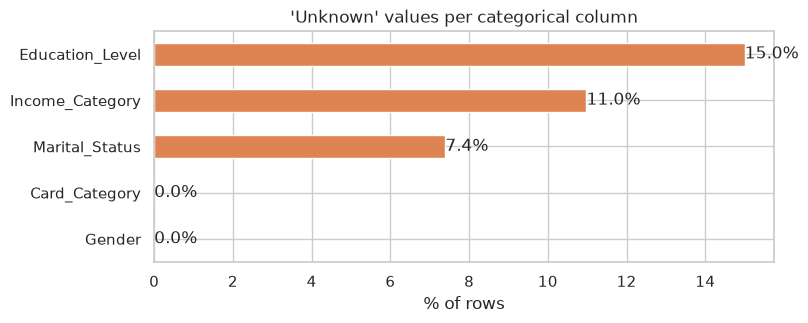

In [12]:
unknown_pct = (df[cat_cols] == "Unknown").mean().mul(100).sort_values()
rows_with_unknown = (df[cat_cols] == "Unknown").any(axis=1).mean() * 100
print(f"Rows with at least one 'Unknown': {rows_with_unknown:.1f}%")

ax = unknown_pct.plot.barh(color=PALETTE["Attrited"], figsize=(8, 3))
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_xlabel("% of rows")
ax.set_title("'Unknown' values per categorical column")
plt.show()

**Observation:** `Unknown` appears in Education_Level (15.0%), Income_Category (11.0%) and Marital_Status (7.4%). In total **30.1% of rows** have at least one `Unknown`.

**Action needed? No cleaning - keep `Unknown` as its own category** (it gets its own one-hot column). Why not the usual fixes:
- **Drop the rows?** No - we would lose ~3,000 customers (30%), including ~500 churners.
- **Fill with the most common value (mode)?** No - that invents information. Churn among `Unknown` customers (16.8-17.2%) is slightly *above* average, so "unknown" may itself be a signal (e.g. customers who share less with the bank); replacing it would erase that signal.

## Step 5: Duplicate rows
**What / Why:** identical rows give some customers extra weight and can leak between train and test sets.

In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


**Observation:** 0 duplicate rows.

**Action needed? No.** Every row is a distinct customer, so there is no double-counting and no risk of the same row landing in both train and test.

## Step 6: Class imbalance
**What / Why:** if one class is much bigger, a model can score high accuracy by always predicting the big class. We need to know this before choosing metrics.

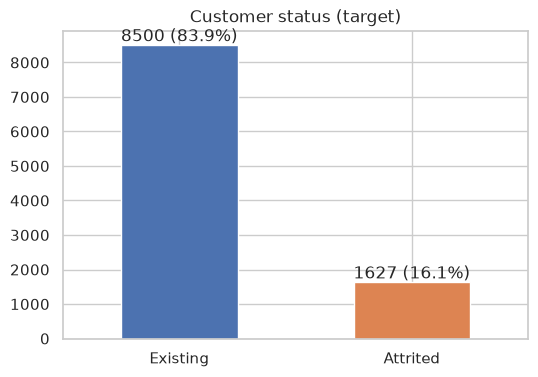

In [14]:
counts = plot_df["Status"].value_counts()
ax = counts.plot.bar(color=[PALETTE[s] for s in counts.index], rot=0, figsize=(6, 4))
ax.bar_label(ax.containers[0], labels=[f"{n} ({n / counts.sum():.1%})" for n in counts])
ax.set_title("Customer status (target)")
ax.set_xlabel("")
plt.show()

**Observation:** 83.9% Existing vs **16.1% Attrited**. A model that always says "Existing" would already get ~84% accuracy while catching zero churners.

**Action needed? Partly.**
- **Yes:** use a **stratified** train/test split so both sets keep the 16% churn rate, and compare models on **F1, MCC and AUC**, not accuracy alone.
- **No resampling (SMOTE / oversampling) for now.** 16% is a *moderate* imbalance - 1,627 churners is enough for the models to learn the pattern. SMOTE creates synthetic customers that never existed, and if applied before the split it leaks fake rows into the test set. The right order is: train a baseline first, and only if Recall for churners is poor, add `class_weight="balanced"` (on training data only).

## Step 7: Outliers
**What / Why:** outliers are values far away from the rest. They can pull linear models and distance-based models (KNN, SVM) towards extreme points. Each numeric feature is shown as a distribution (left) and a box plot (right); dots outside the whiskers are outliers by the 1.5 x IQR rule.

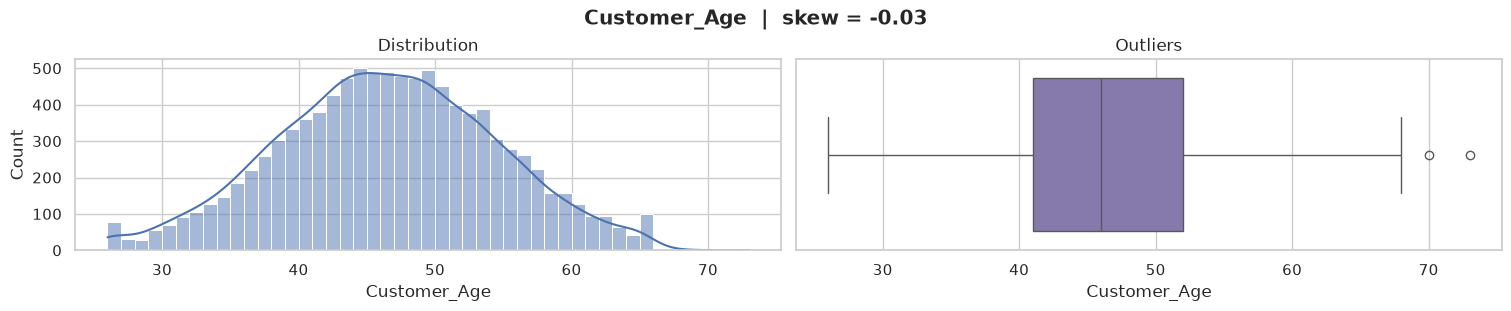

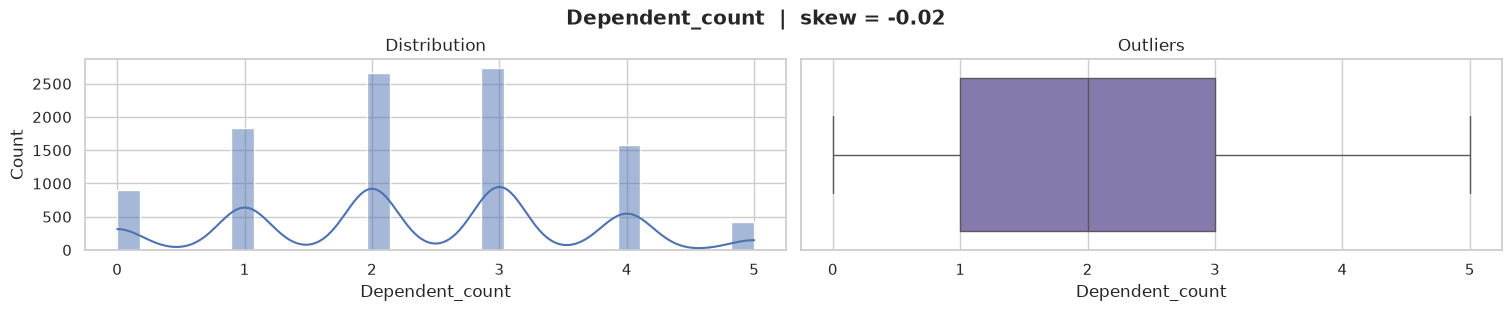

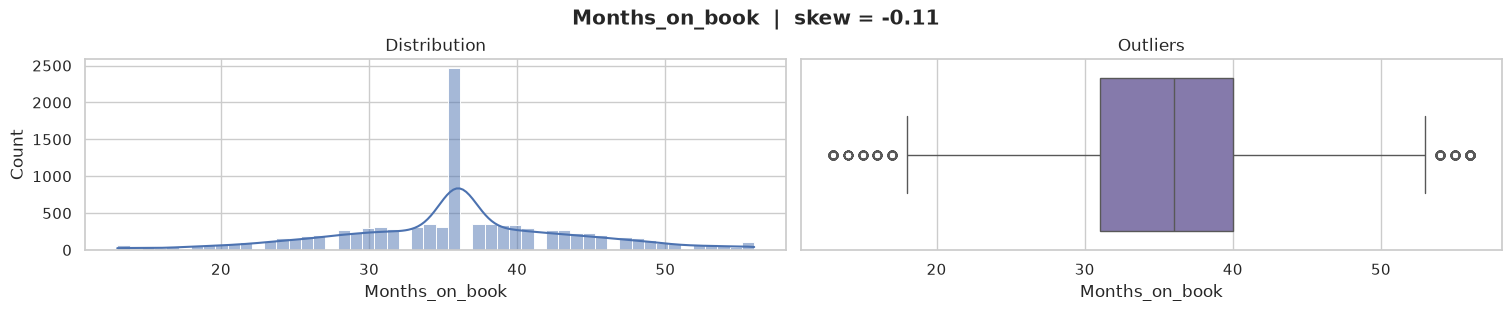

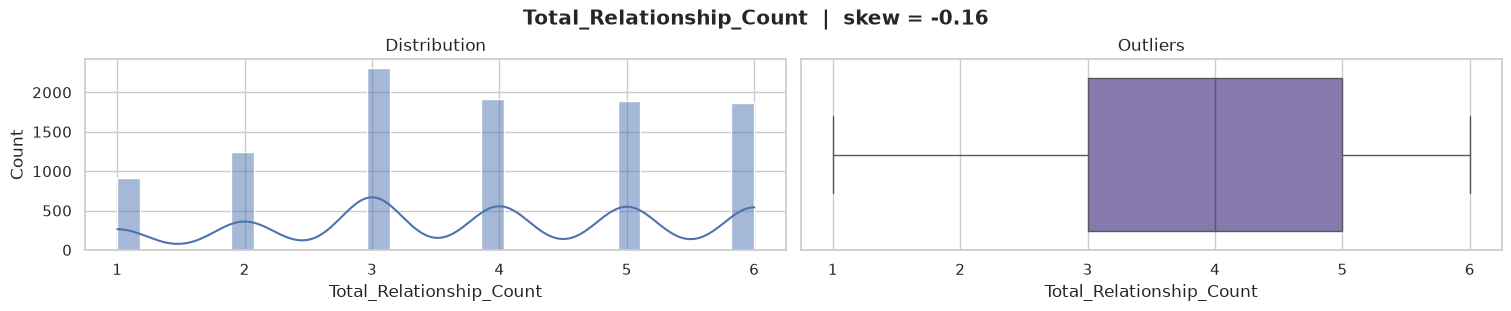

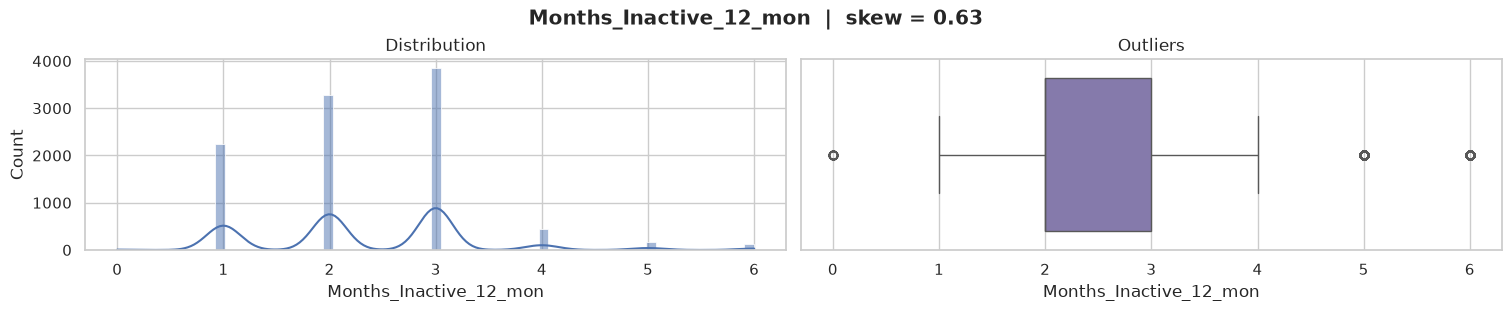

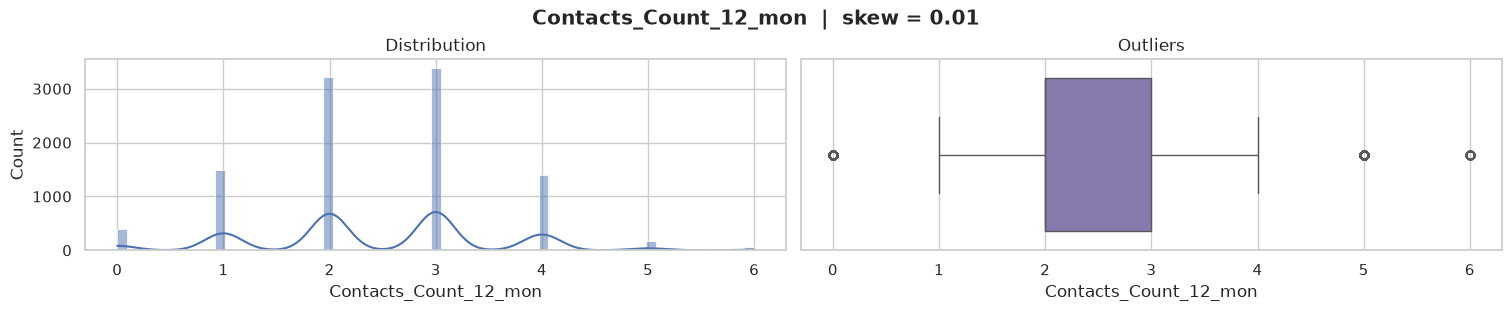

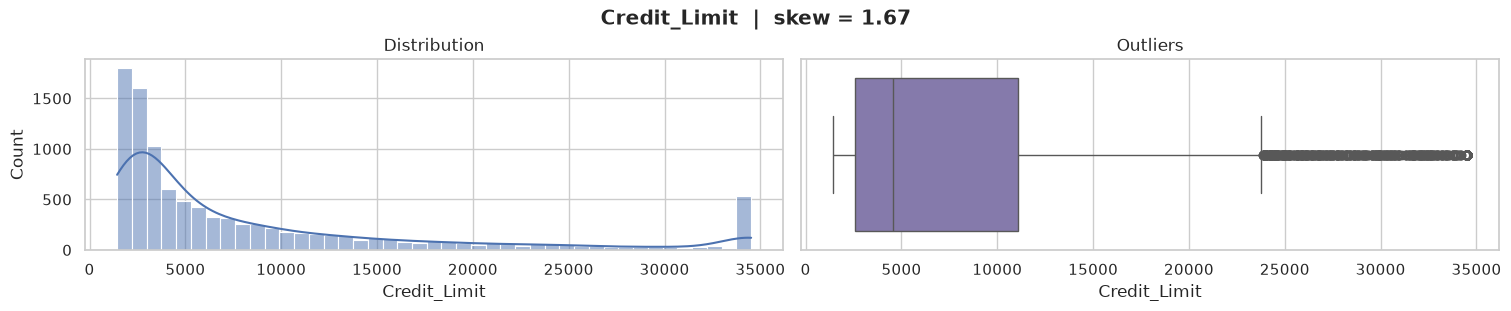

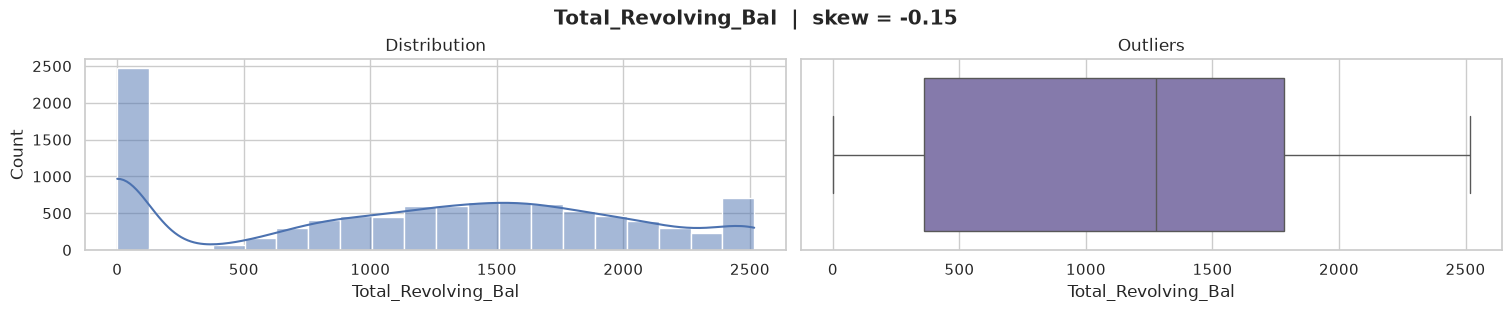

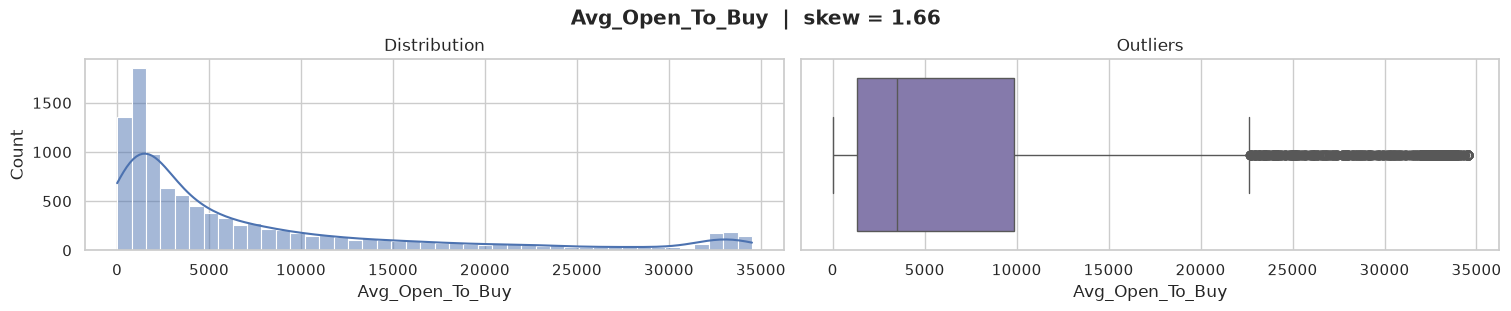

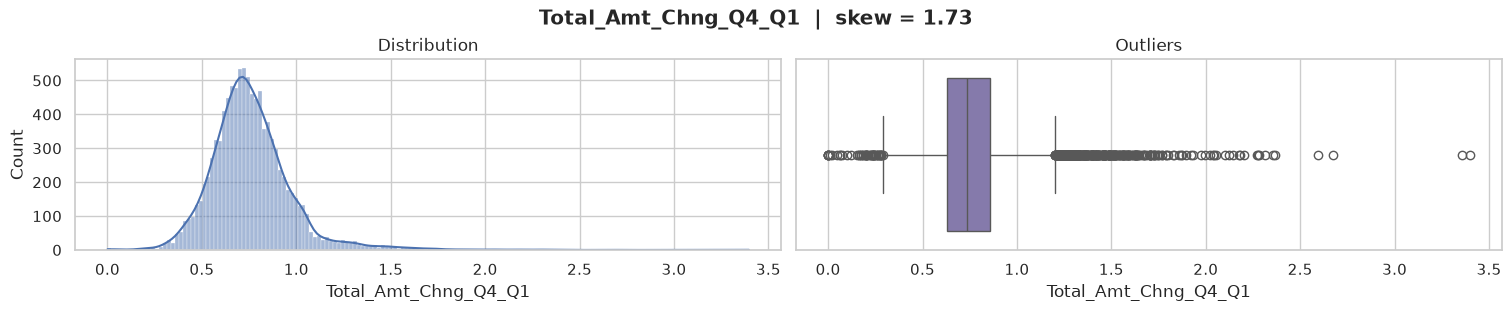

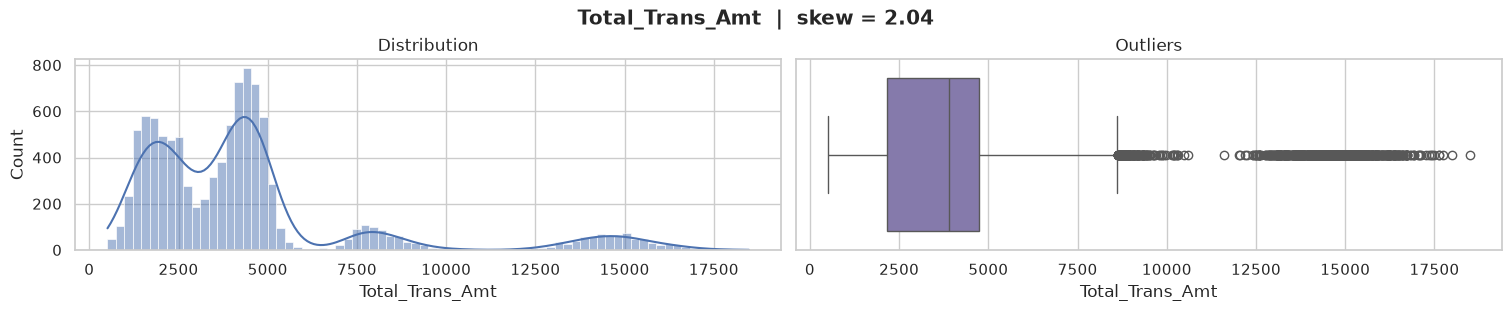

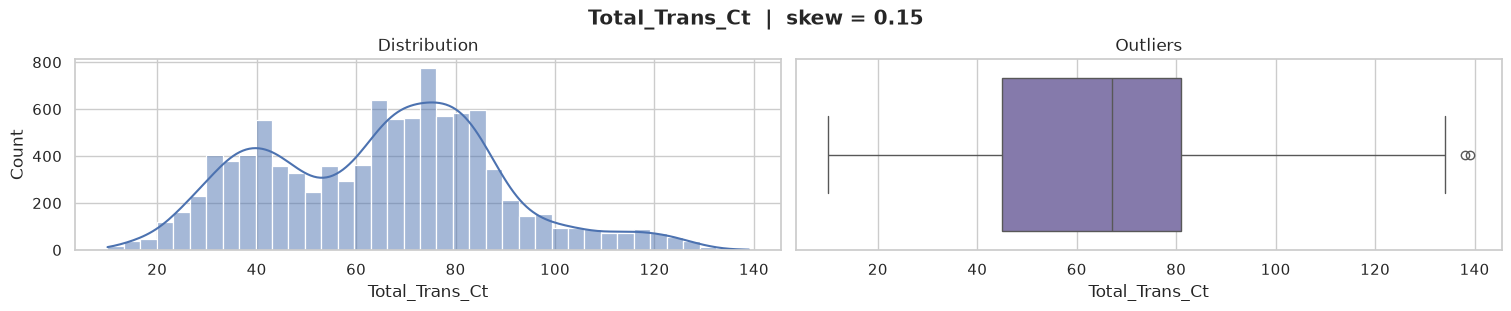

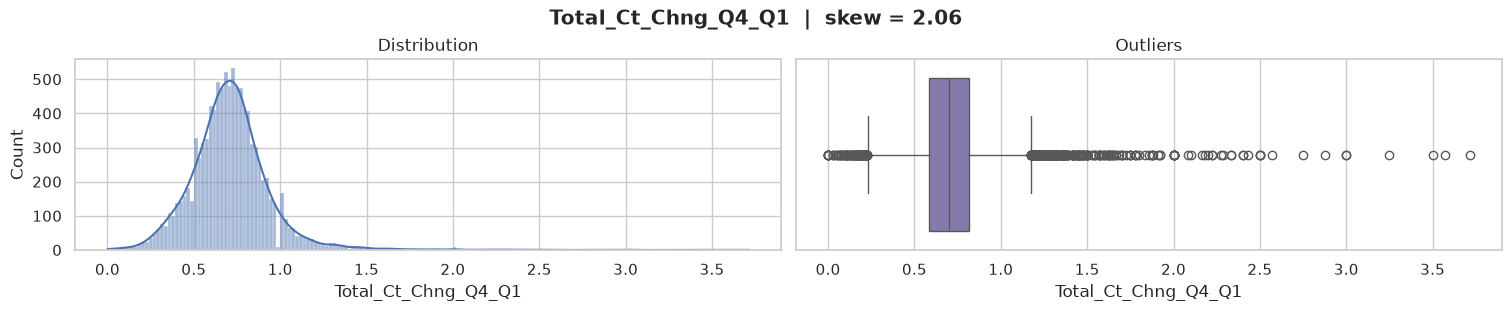

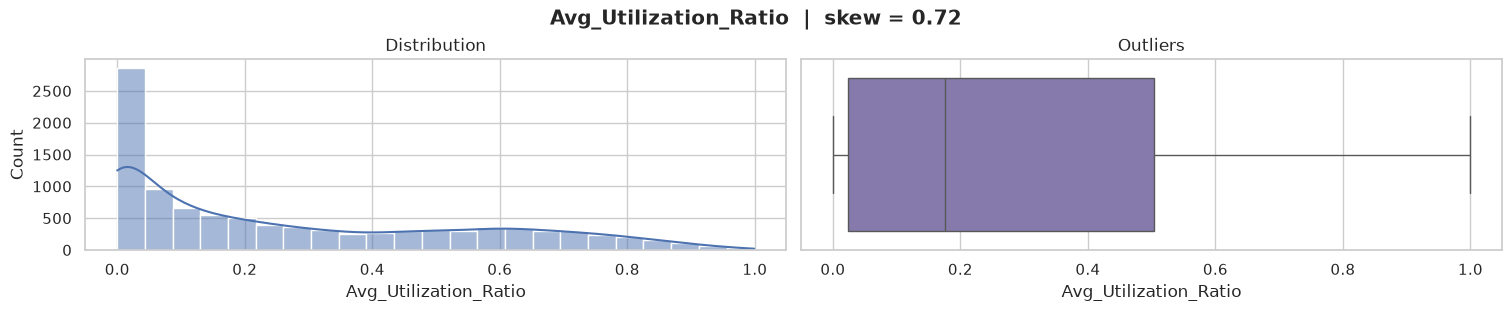

In [15]:
numerical_features = [
    "Customer_Age",
    "Dependent_count",
    "Months_on_book",
    "Total_Relationship_Count",
    "Months_Inactive_12_mon",
    "Contacts_Count_12_mon",
    "Credit_Limit",
    "Total_Revolving_Bal",
    "Avg_Open_To_Buy",
    "Total_Amt_Chng_Q4_Q1",
    "Total_Trans_Amt",
    "Total_Trans_Ct",
    "Total_Ct_Chng_Q4_Q1",
    "Avg_Utilization_Ratio",
]

for col in numerical_features:  # distribution + box plot for each numeric feature
    fig, ax = plt.subplots(1, 2, constrained_layout=True, figsize=(15, 3))
    sns.histplot(df[col], kde=True, ax=ax[0], color=PALETTE["Existing"]).set(title="Distribution")
    sns.boxplot(x=df[col], ax=ax[1], color="#8172B3").set(title="Outliers")
    plt.suptitle(f"{col}  |  skew = {df[col].skew():.2f}", weight="bold")
    plt.show()


In [16]:
q1, q3 = df[numerical_features].quantile(0.25), df[numerical_features].quantile(0.75)
iqr = q3 - q1
is_outlier = (df[numerical_features] < q1 - 1.5 * iqr) | (df[numerical_features] > q3 + 1.5 * iqr)

outlier_pct = is_outlier.mean().mul(100).round(1).sort_values(ascending=False)
print("% of rows flagged as outliers:")
print(outlier_pct[outlier_pct > 0].to_string())

rows = is_outlier.any(axis=1)
print(f"\nIf we removed every outlier row: {rows.sum()} rows lost ({rows.mean():.1%}), "
      f"including {df.loc[rows, TARGET].sum()} of {df[TARGET].sum()} attrited customers")
print("Customers at the maximum Credit_Limit (34,516):", (df["Credit_Limit"] == 34516).sum())

% of rows flagged as outliers:
Credit_Limit              9.7
Avg_Open_To_Buy           9.5
Total_Trans_Amt           8.8
Contacts_Count_12_mon     6.2
Total_Amt_Chng_Q4_Q1      3.9
Total_Ct_Chng_Q4_Q1       3.9
Months_on_book            3.8
Months_Inactive_12_mon    3.3

If we removed every outlier row: 3326 rows lost (32.8%), including 505 of 1627 attrited customers
Customers at the maximum Credit_Limit (34,516): 508


**Observation:**
- 8 of 14 numeric features have outliers; most in Credit_Limit (9.7%), Avg_Open_To_Buy (9.5%) and Total_Trans_Amt (8.8%).
- They are **genuine customers**, not errors - e.g. 508 customers sit exactly at the bank's maximum credit limit, and heavy spenders have high transaction amounts.
- Removing them would delete **32.8% of the data**, including 505 of the 1,627 churners.

**Action needed? No removal and no capping.** Why:
- Outlier treatment is for **errors** (typos, impossible values). These are real, valid customers.
- **Removing** them costs 32.8% of the data and 31% of the churners - the class we care about most.
- **Capping** (clipping to the IQR limits) would rewrite real values, e.g. turn genuine high spenders into average ones. High `Total_Trans_Amt` is one of the clearest *loyalty* signals, so capping would hide useful information.
- The app's test CSV will contain such customers too; the model must learn to handle them, not be trained on a cleaned-up world.

Their pull on LR / KNN / SVM is reduced by the power transform in Step 11. Decision Tree splits on thresholds, so it is not affected by outliers at all.

## Step 8: Skewness
**What / Why:** skewness measures how lopsided a distribution is (0 = symmetric, |skew| > 1 = highly skewed). Logistic Regression, KNN, SVM and Gaussian Naive Bayes work best when features are roughly symmetric (Gaussian NB literally assumes a bell curve).

In [17]:
skew = df[numerical_features].skew().round(2).sort_values(ascending=False)
skew.to_frame("skew").assign(level=pd.cut(skew.abs(), [-1, 0.5, 1, 99], labels=["ok", "moderate", "high"]))

,skew,level
Total_Ct_Chng_Q4_Q1,2.06,high
Total_Trans_Amt,2.04,high
Total_Amt_Chng_Q4_Q1,1.73,high
Credit_Limit,1.67,high
Avg_Open_To_Buy,1.66,high
Avg_Utilization_Ratio,0.72,moderate
Months_Inactive_12_mon,0.63,moderate
Total_Trans_Ct,0.15,ok
Contacts_Count_12_mon,0.01,ok
Dependent_count,-0.02,ok


**Observation:** 5 features are highly right-skewed: Total_Ct_Chng_Q4_Q1 (2.06), Total_Trans_Amt (2.04), Total_Amt_Chng_Q4_Q1 (1.73), Credit_Limit (1.67), Avg_Open_To_Buy (1.66). They have a long tail of large values.

**Action needed? Yes - Yeo-Johnson power transform** on all numeric features (Step 11). Why this and not a plain log:
- `log` fails on 0 values, and several features contain 0 (e.g. Total_Revolving_Bal, Avg_Utilization_Ratio); Yeo-Johnson handles zeros.
- It learns the best transform strength **per feature** from the training data, instead of one fixed formula for all.
- It also standardizes (mean 0, std 1), so no separate scaler is needed.

Decision Tree doesn't need it (splits are unaffected by monotonic transforms), but it doesn't hurt it either, so one shared pipeline is used for all five models.

## Step 9: Correlation between features
**What / Why:** two features that move together almost perfectly carry the same information. This adds noise, makes Logistic Regression coefficients unstable, and breaks Naive Bayes' assumption that features are independent.

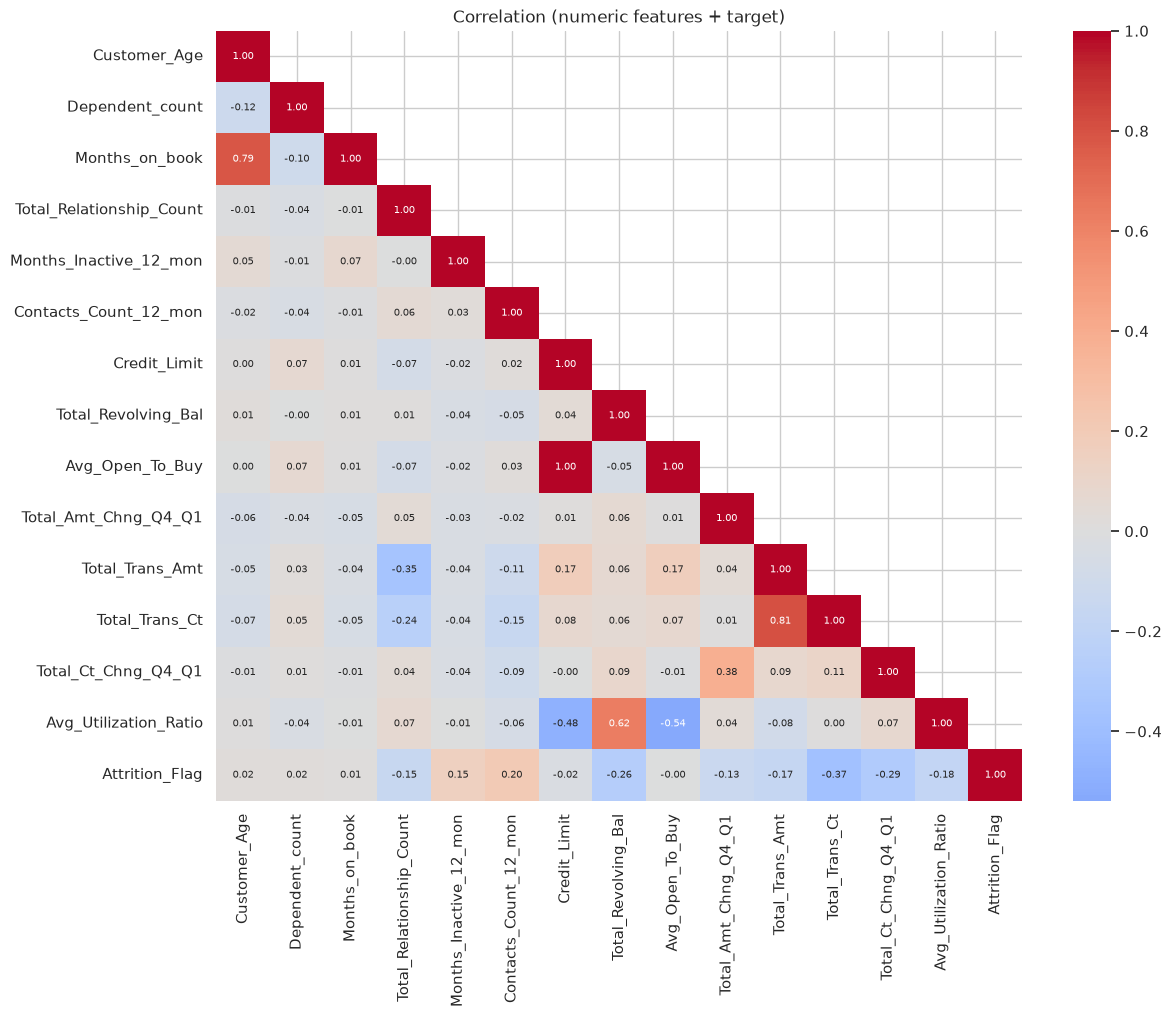

Pairs with |r| > 0.7:
Credit_Limit     Avg_Open_To_Buy    0.996
Total_Trans_Amt  Total_Trans_Ct     0.807
Customer_Age     Months_on_book     0.789


In [18]:
corr = df[num_cols + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(13, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation (numeric features + target)")
plt.show()

pairs = corr.loc[num_cols, num_cols].where(np.triu(np.ones((len(num_cols),) * 2, dtype=bool), k=1)).stack()
print("Pairs with |r| > 0.7:")
print(pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False).round(3).to_string())

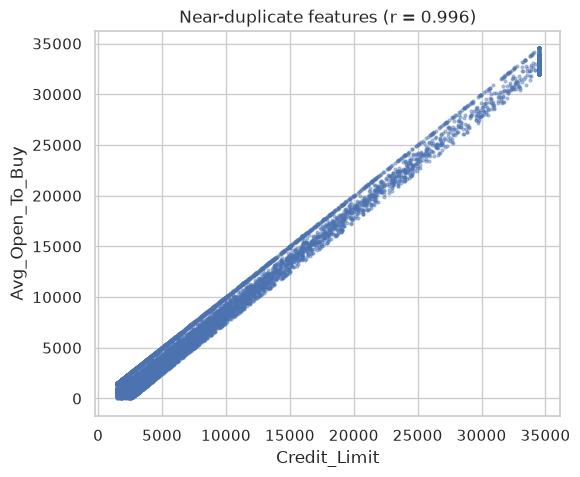

In [19]:
r = df["Credit_Limit"].corr(df["Avg_Open_To_Buy"])
plt.figure(figsize=(6, 5))
plt.scatter(df["Credit_Limit"], df["Avg_Open_To_Buy"], s=4, alpha=0.4, color=PALETTE["Existing"])
plt.xlabel("Credit_Limit")
plt.ylabel("Avg_Open_To_Buy")
plt.title(f"Near-duplicate features (r = {r:.3f})")
plt.show()

**Observation:**
- `Credit_Limit` vs `Avg_Open_To_Buy`: **r = 0.996** - practically the same column (open-to-buy = limit - balance, and balances are small compared to limits).
- `Total_Trans_Amt` vs `Total_Trans_Ct`: r = 0.807 and `Customer_Age` vs `Months_on_book`: r = 0.789 - related but each still adds different information (amount vs count, age vs tenure).

**Action needed?**
- **Yes - drop `Avg_Open_To_Buy`.** At r = 0.996 it adds no new information, only redundancy (and it double-counts the same signal for Naive Bayes). Credit_Limit is kept because it is easier to explain. Features used for modelling: **18** (still above the 12-feature minimum).
- **No - keep the 0.81 and 0.79 pairs.** They are below the usual ~0.9 threshold and mean different things: *how much* is spent vs *how often*, and *age* vs *time with the bank*. Dropping either would lose real information; Logistic Regression's built-in regularization already handles moderate correlation.

## Step 10: Train / test split
**What / Why:** models must be judged on customers they have never seen. 80% of the rows train the models, 20% are kept aside for testing. `stratify` keeps the 16% churn rate in both parts; a fixed seed (42) gives every model the same split.

In [20]:
from common import get_train_test

X_train, X_test, y_train, y_test = get_train_test()
test_df = save_test_data()

print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)} | Features: {X_train.shape[1]}")
print(f"Churn rate -> train: {y_train.mean():.1%}, test: {y_test.mean():.1%}")
print(f"Saved test_data.csv: {test_df.shape}")

Train rows: 8101 | Test rows: 2026 | Features: 18
Churn rate -> train: 16.1%, test: 16.0%
Saved test_data.csv: (2026, 19)


**Observation:** 8,101 train rows / 2,026 test rows, churn rate 16.1% (train) and 16.0% (test) - practically identical. 18 features (Avg_Open_To_Buy already dropped).

**Action needed? Yes - split before any fitting.** `test_data.csv` is saved in **raw form** (not encoded/scaled) - this is the file uploaded to the Streamlit app, and the saved model pipelines do the preprocessing themselves.

## Step 11: Encoding + scaling (inside the model pipeline)
**What / Why:**
- **One-hot encoding** - models need numbers, so each category becomes its own 0/1 column (e.g. `Gender_F`, `Gender_M`). One-hot is used instead of label encoding because the categories have no natural order for most columns.
- **Power transform (Yeo-Johnson)** - fixes the skew found in Step 8 and standardizes every numeric feature to mean 0 / std 1, so KNN and SVM don't let large-valued features (Credit_Limit in thousands) dominate small ones (Dependent_count 0-5).

Both are **learned from the training data only** and stored inside each saved model, so test data and the app's uploaded CSV get exactly the same transformation (no data leakage).

In [21]:
from common import build_preprocessor

prep = build_preprocessor(X_train).fit(X_train)
print(f"{X_train.shape[1]} input features -> {prep.transform(X_train).shape[1]} model columns after one-hot encoding")

num_used = X_train.select_dtypes(include="number").columns
transformed = pd.DataFrame(prep.named_transformers_["num"].transform(X_train[num_used]), columns=num_used)
pd.DataFrame({"skew before": X_train[num_used].skew(), "skew after": transformed.skew()}).round(2)

18 input features -> 36 model columns after one-hot encoding


,skew before,skew after
Customer_Age,-0.03,-0.02
Dependent_count,-0.02,-0.11
Months_on_book,-0.10,0.03
Total_Relationship_Count,-0.17,-0.14
Months_Inactive_12_mon,0.64,-0.01
Contacts_Count_12_mon,0.00,-0.03
Credit_Limit,1.68,0.10
Total_Revolving_Bal,-0.16,-0.87
Total_Amt_Chng_Q4_Q1,1.80,-0.09
Total_Trans_Amt,2.05,0.00


**Observation:** the 5 categorical features expand into one-hot columns; after the power transform the highly skewed features drop to almost 0 (e.g. Total_Trans_Amt 2.05 -> 0.00, Total_Ct_Chng_Q4_Q1 2.25 -> -0.08). One exception: Total_Revolving_Bal goes from -0.16 to -0.87, because 24% of customers have a balance of exactly 0 - a spike that no transform can spread out. This is acceptable: that zero-balance group is itself a strong churn signal (Features vs target), and the feature is still standardized.

**Action needed? Yes - this preprocessor is the first step of every model pipeline** in notebooks 01-05.

# Features vs target
**What / Why:** before modelling, check which features actually differ between customers who left and those who stayed. These are the features we expect the models to rely on.

### Attrition rate by category
Bars show the % of customers in each category who left; the dashed line is the overall rate (16.1%).

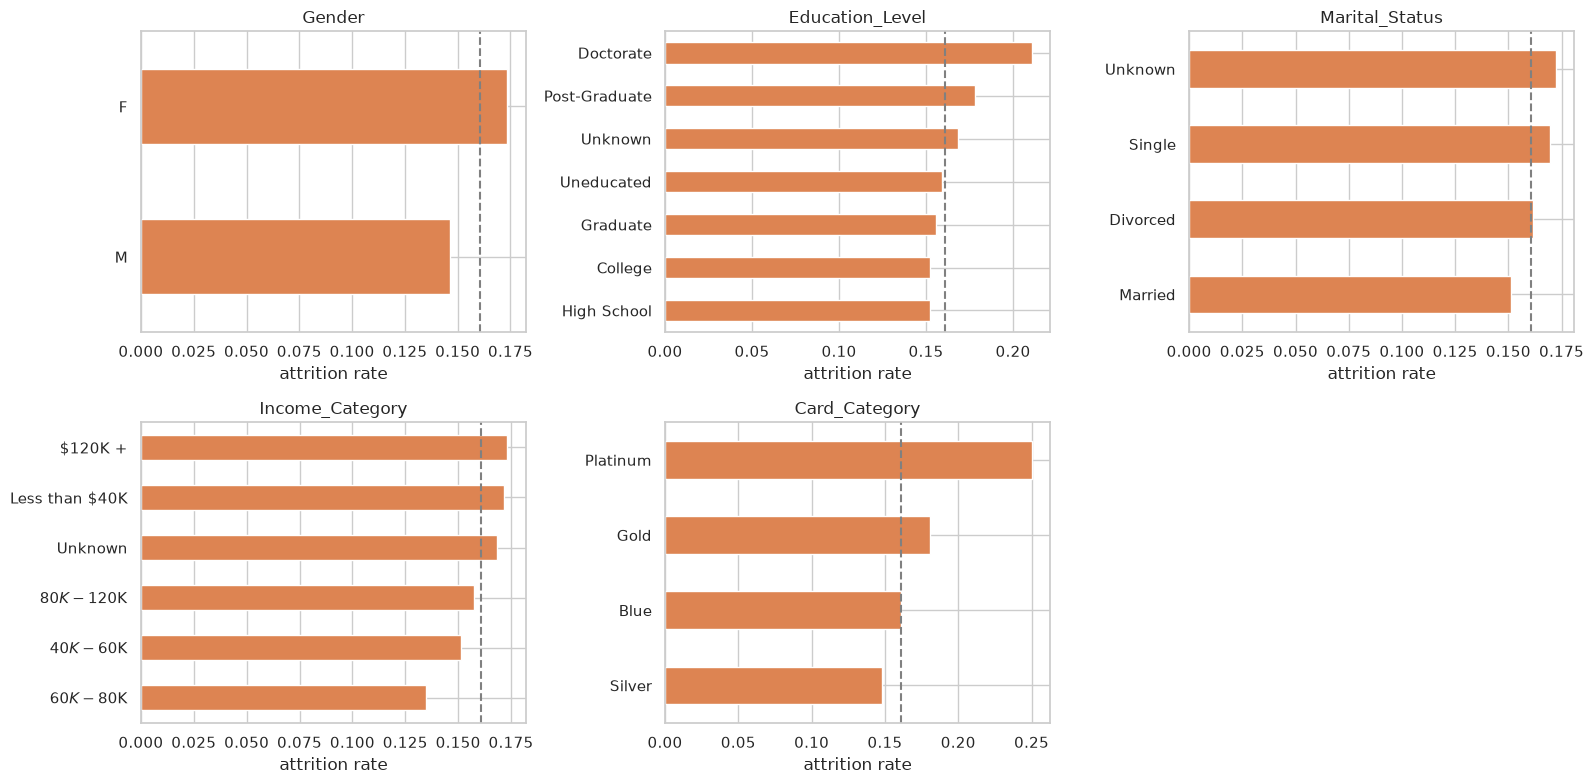

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
overall = df[TARGET].mean()
for ax, col in zip(axes.flat, cat_cols):
    df.groupby(col)[TARGET].mean().sort_values().plot.barh(ax=ax, color=PALETTE["Attrited"])
    ax.axvline(overall, ls="--", c="grey")
    ax.set_title(col)
    ax.set_xlabel("attrition rate")
    ax.set_ylabel("")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

**Observation:**
- Gender: women leave slightly more (17.4%) than men (14.6%).
- Education: Doctorate has the highest churn (21.1%); other levels are 15-18%.
- Income: lowest churn in $60K-$80K (13.5%); highest at both ends (< $40K and $120K+ ~17%).
- Card: Platinum 25% but only 20 customers, so not reliable.
- **Overall: categorical features differ only by a few % points -> weak predictors on their own.**

### Numeric distributions by status
Where the blue (Existing) and orange (Attrited) curves are clearly apart, the feature separates the two groups well.

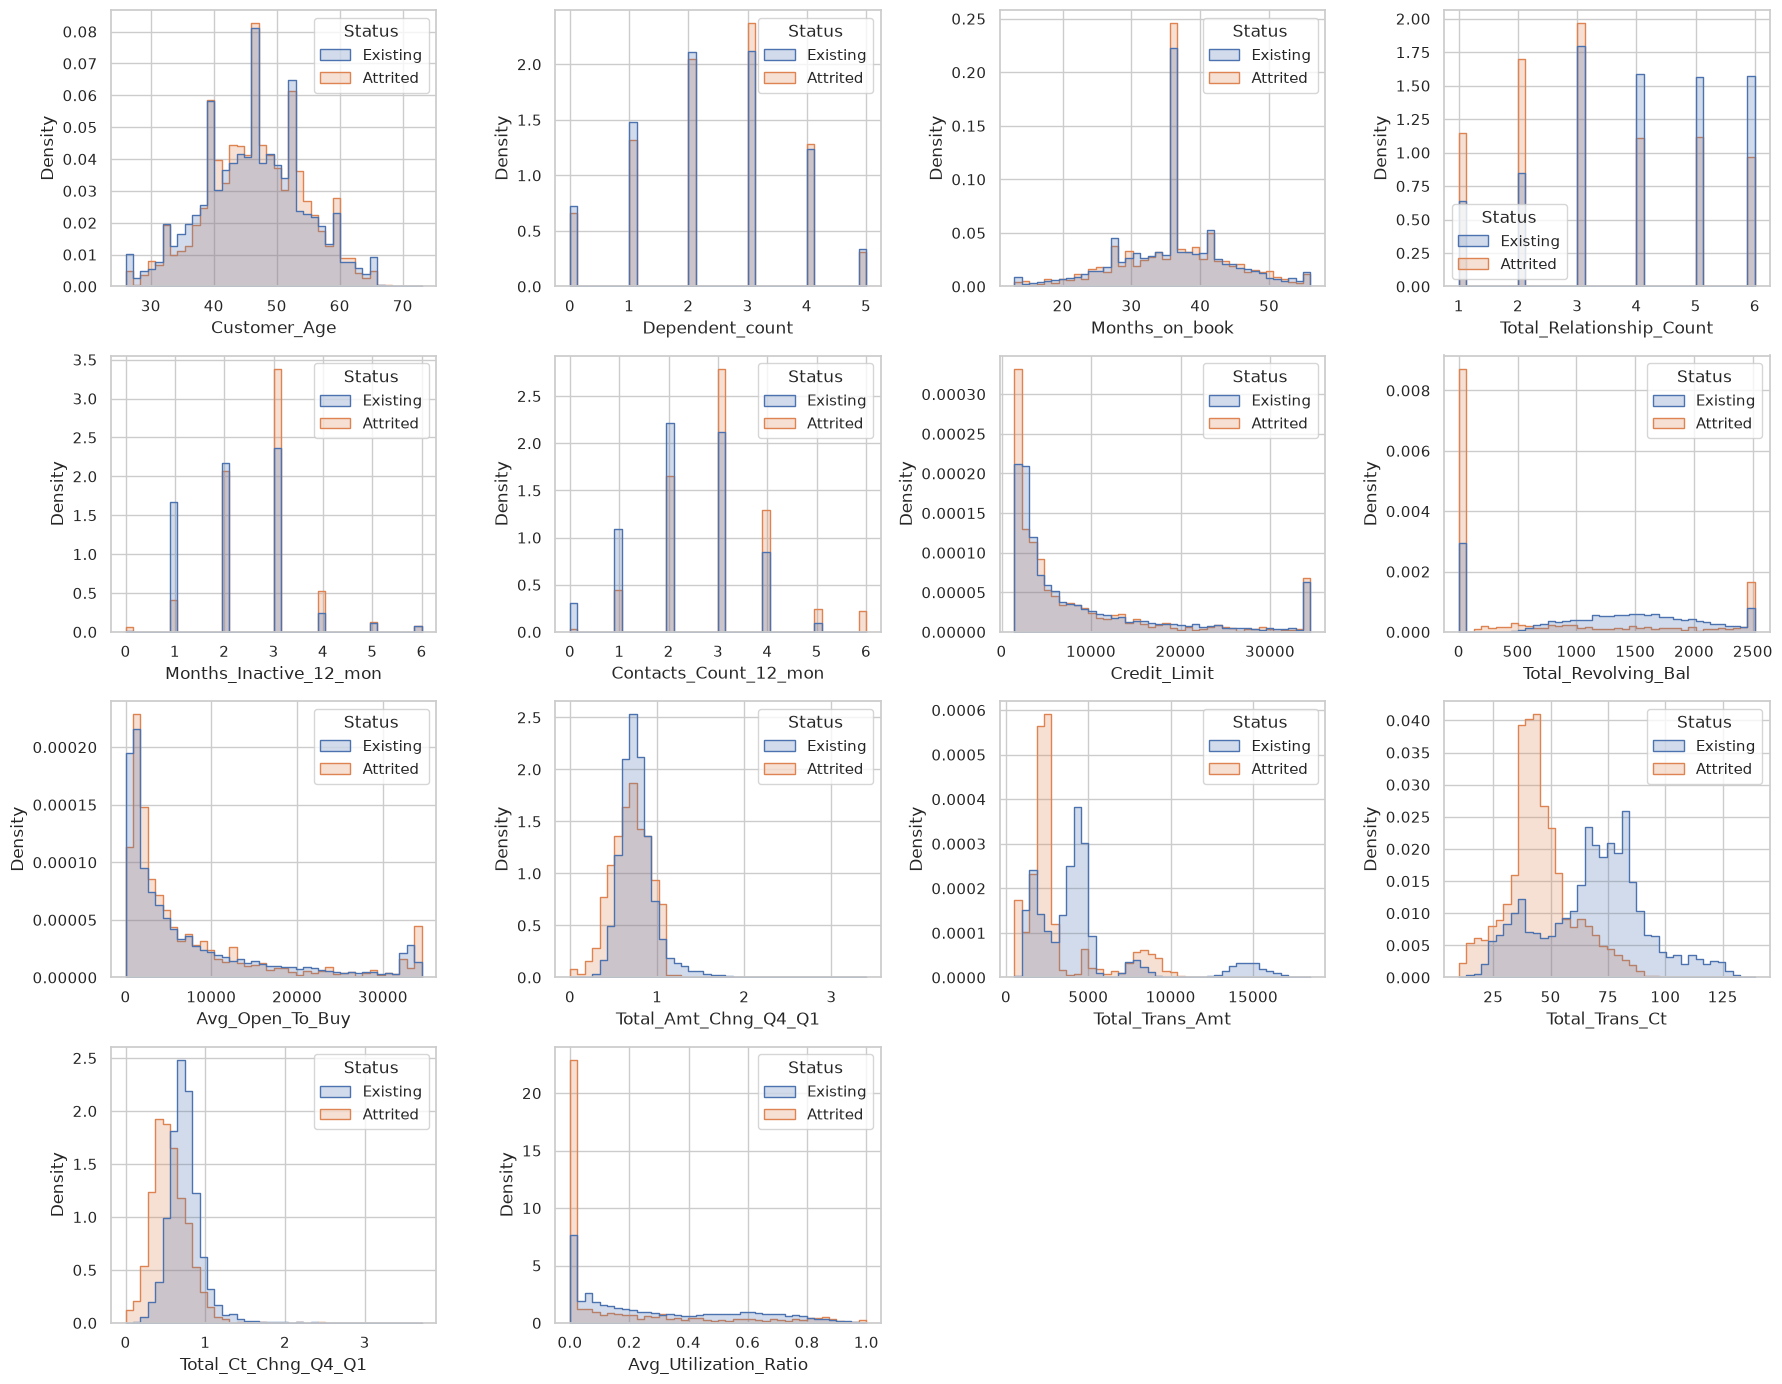

In [23]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=plot_df, x=col, hue="Status", palette=PALETTE, stat="density",
                 common_norm=False, bins=40, element="step", ax=ax)
for ax in axes.flat[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Observation (median Existing vs Attrited):**
- **Total_Trans_Ct: 71 vs 43** and **Total_Trans_Amt: 4,100 vs 2,329** - customers who leave use the card much less.
- **Total_Revolving_Bal: 1,364 vs 0** and **Avg_Utilization_Ratio: 0.21 vs 0.00** - most churners carry no balance.
- **Total_Ct_Chng_Q4_Q1: 0.72 vs 0.53** - churners' activity was already dropping during the year.
- Total_Relationship_Count 4 vs 3, Months_Inactive 2 vs 3, Contacts_Count 2 vs 3 - fewer products, more inactivity, more calls to the bank.
- Age, Dependent_count and Months_on_book look the same for both groups -> little predictive value.

# Summary of preprocessing

| # | Step | Observation | Action? | Why |
|---|---|---|---|---|
| 1 | Drop columns | ID + 2 leaked Naive Bayes columns | **Yes** - dropped (23 -> 20 cols) | ID has no meaning; leaked columns give fake scores |
| 2 | Encode target | Text labels | **Yes** - Attrited = 1 | Metrics must measure churners |
| 3 | Missing values | 0 NaN | **No** | Nothing to fill |
| 4 | Hidden missing | `Unknown` in 30.1% of rows | **No cleaning** - kept as category | Dropping loses 30% of data; imputing invents values and erases a possible signal |
| 5 | Duplicates | 0 | **No** | Every row is a distinct customer |
| 6 | Class imbalance | 16.1% churn | **Partly** - stratified split + F1/MCC/AUC | Moderate imbalance; no SMOTE (synthetic rows, leakage risk); try class weights only if recall is poor |
| 7 | Outliers | Up to 9.7% per feature, genuine values | **No removal / capping** | Real customers; removal loses 31% of churners; capping hides real signal |
| 8 | Skewness | 5 features with skew > 1.6 | **Yes** - Yeo-Johnson | Handles zeros, tuned per feature, also standardizes |
| 9 | Correlation | r = 0.996 (Credit_Limit / Avg_Open_To_Buy); 0.81, 0.79 others | **Yes** for 0.996 pair, **No** for the rest | Exact duplicate info vs. related-but-different meaning |
| 10 | Train/test split | 8,101 / 2,026, churn 16.1% / 16.0% | **Yes** - stratified 80/20 | Fair, unseen test set; same split for all models |
| 11 | Encoding + scaling | Categorical text, mixed scales | **Yes** - one-hot + power transform in pipeline | Fit on train only; app gets identical preprocessing |
| - | Weak features (Age, Dependents, Months_on_book, categoricals) | Little difference between classes | **No drop** | Only 18 features; models can down-weight them, and dropping could lose interactions |
| - | Rare category (Platinum card, 20 customers) | Too small to trust | **No merge** | One-hot handles it; merging changes meaning for a tiny gain |

**Strongest signals for churn:** low transaction count and amount, zero revolving balance / utilization, falling activity from Q1 to Q4, fewer bank products and more inactive months.